In [8]:
import pandas as pd
import numpy as np
import keras
import warnings
warnings.filterwarnings(action="ignore")
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten
from keras.layers import Conv2D, MaxPooling2D
from keras import backend as K

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy
# from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import TensorBoard,EarlyStopping

import sklearn.metrics as metrics
from keras.callbacks import LearningRateScheduler
# from keras.preprocessing.image import ImageDataGenerator
annealer = LearningRateScheduler(lambda x: 1e-3 * 0.95 ** x, verbose=0)

In [9]:
import os
import pandas as pd

MildDemented_dir = r'/Users/aman/Documents/codes/sp2/AugmentedAlzheimerMRI/AugmentedAlzheimerDataset/MildDemented'
ModerateDemented_dir = r'/Users/aman/Documents/codes/sp2/AugmentedAlzheimerMRI/AugmentedAlzheimerDataset/ModerateDemented'
NonDemented_dir = r'/Users/aman/Documents/codes/sp2/AugmentedAlzheimerMRI/AugmentedAlzheimerDataset/NonDemented'
VeryMildDemented_dir = r'/Users/aman/Documents/codes/sp2/AugmentedAlzheimerMRI/AugmentedAlzheimerDataset/VeryMildDemented'

filepaths = []
labels = []
dict_list = [MildDemented_dir, ModerateDemented_dir, NonDemented_dir, VeryMildDemented_dir]
class_labels = ['Mild Demented', 'Moderate Demented', 'Non Demented', 'Very MildDemented']

for i, j in enumerate(dict_list):
    flist = os.listdir(j)
    for f in flist:
        fpath = os.path.join(j, f)
        filepaths.append(fpath)
        labels.append(class_labels[i])

Fseries = pd.Series(filepaths, name="filepaths")
Lseries = pd.Series(labels, name="labels")
Alzheimer_data = pd.concat([Fseries, Lseries], axis=1)
Alzheimer_df = pd.DataFrame(Alzheimer_data)
print(Alzheimer_df.head())
print(Alzheimer_df["labels"].value_counts())

                                           filepaths         labels
0  /Users/aman/Documents/codes/sp2/AugmentedAlzhe...  Mild Demented
1  /Users/aman/Documents/codes/sp2/AugmentedAlzhe...  Mild Demented
2  /Users/aman/Documents/codes/sp2/AugmentedAlzhe...  Mild Demented
3  /Users/aman/Documents/codes/sp2/AugmentedAlzhe...  Mild Demented
4  /Users/aman/Documents/codes/sp2/AugmentedAlzhe...  Mild Demented
labels
Non Demented         9600
Mild Demented        8960
Very MildDemented    8960
Moderate Demented    6464
Name: count, dtype: int64


In [10]:
Alzheimer_df.shape

(33984, 2)

In [11]:
train_images, test_images = train_test_split(Alzheimer_df, test_size=0.3, random_state=42)
train_set, val_set = train_test_split(Alzheimer_df, test_size=0.2, random_state=42)

In [12]:
print(train_set.shape)
print(test_images.shape)
print(val_set.shape)
print(train_images.shape)

(27187, 2)
(10196, 2)
(6797, 2)
(23788, 2)


In [13]:
image_gen = ImageDataGenerator(preprocessing_function= tf.keras.applications.mobilenet_v2.preprocess_input)
train = image_gen.flow_from_dataframe(dataframe= train_set,x_col="filepaths",y_col="labels",
                                      target_size=(244,244),
                                      color_mode='rgb',
                                      class_mode="categorical", #used for Sequential Model
                                      batch_size=32,
                                      shuffle=False            #do not shuffle data
                                     )
test = image_gen.flow_from_dataframe(dataframe= test_images,x_col="filepaths", y_col="labels",
                                     target_size=(244,244),
                                     color_mode='rgb',
                                     class_mode="categorical",
                                     batch_size=32,
                                     shuffle= False
                                    )
val = image_gen.flow_from_dataframe(dataframe= val_set,x_col="filepaths", y_col="labels",
                                    target_size=(244,244),
                                    color_mode= 'rgb',
                                    class_mode="categorical",
                                    batch_size=32,
                                    shuffle=False
                                   )

Found 27187 validated image filenames belonging to 4 classes.
Found 10196 validated image filenames belonging to 4 classes.
Found 6797 validated image filenames belonging to 4 classes.


In [14]:
classes=list(train.class_indices.keys())
print (classes)

['Mild Demented', 'Moderate Demented', 'Non Demented', 'Very MildDemented']


In [15]:
def show_zheimer_images(image_gen):
    test_dict = test.class_indices
    classes = list(test_dict.keys())
    images, labels=next(image_gen) # get a sample batch from the generator
    plt.figure(figsize=(20,20))
    length = len(labels)
    if length<25:
        r=length
    else:
        r=25
    for i in range(r):
        plt.subplot(5,5,i+1)
        image=(images[i]+1)/2 #scale images between 0 and 1
        plt.imshow(image)
        index=np.argmax(labels[i])
        class_name=classes[index]
        plt.title(class_name, color="green",fontsize=16)
        plt.axis('off')
    plt.show()

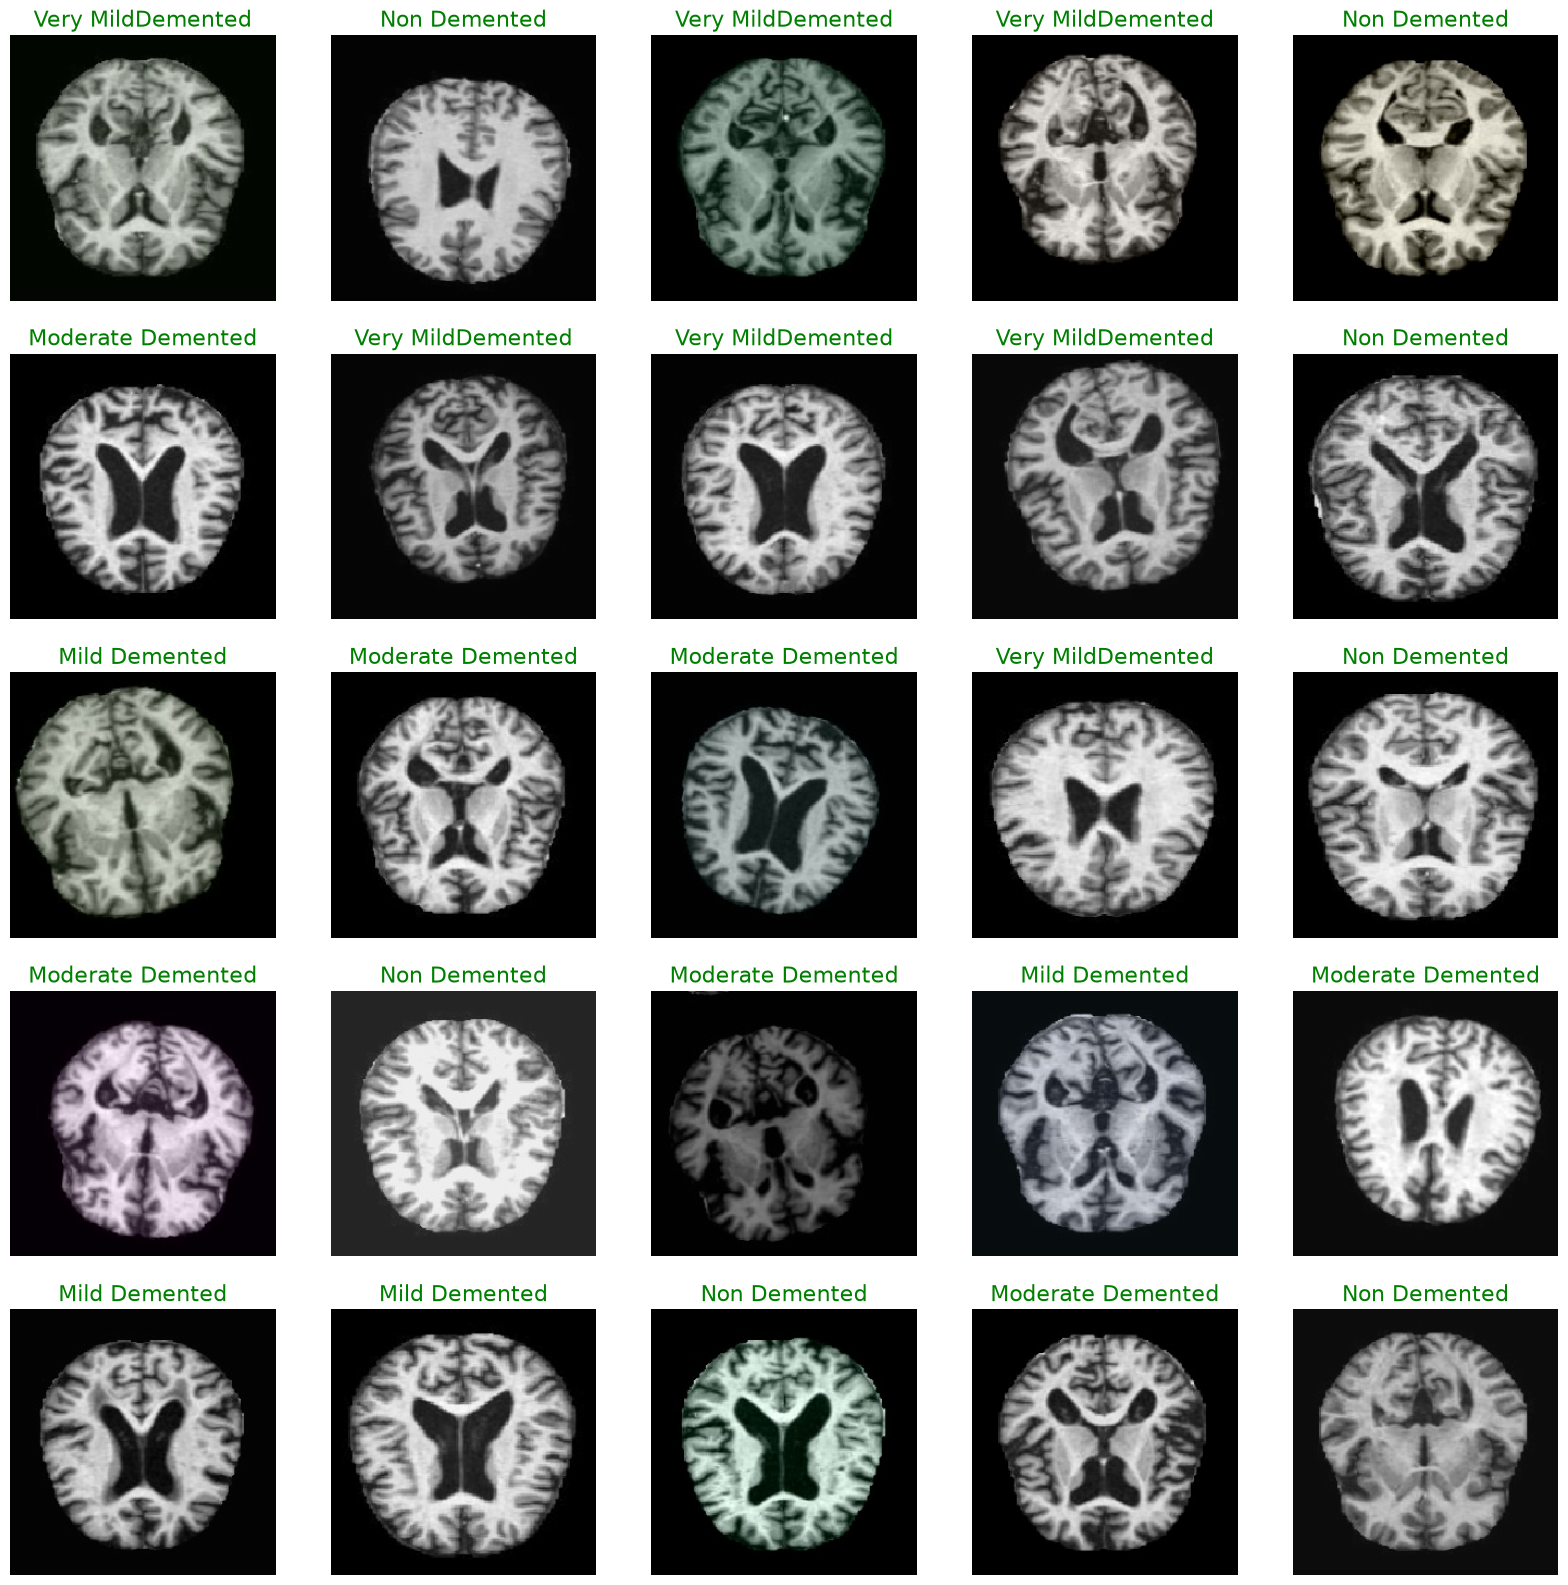

In [16]:
show_zheimer_images(train)

In [17]:
from tensorflow.keras.applications import DenseNet201
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

base_model = DenseNet201(weights='imagenet', include_top=False, input_shape=(244, 244, 3), pooling=None)

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)  # Add your custom dense layers here
predictions = Dense(4, activation='softmax')(x)  # Modify num_classes according to your problem

model = Model(inputs=base_model.input, outputs=predictions)

for layer in base_model.layers:
    layer.trainable = False

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# model.summary()

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [20]:
history = model.fit(train, epochs=20, validation_data=val, validation_freq=1)

Epoch 1/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 1945s 2s/step - accuracy: 0.8077 - loss: 0.4497 - val_accuracy: 0.7946 - val_loss: 0.4788
Epoch 2/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 1994s 2s/step - accuracy: 0.8313 - loss: 0.3958 - val_accuracy: 0.8179 - val_loss: 0.4351
Epoch 3/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 1996s 2s/step - accuracy: 0.8609 - loss: 0.3411 - val_accuracy: 0.8442 - val_loss: 0.3674
Epoch 4/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 2540s 3s/step - accuracy: 0.8780 - loss: 0.2982 - val_accuracy: 0.8427 - val_loss: 0.3674
Epoch 5/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 2484s 3s/step - accuracy: 0.8934 - loss: 0.2697 - val_accuracy: 0.8736 - val_loss: 0.3188
Epoch 6/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 2218s 3s/step - accuracy: 0.9061 - loss: 0.2344 - val_accuracy: 0.8764 - val_loss: 0.2963
Epoch 7/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 2101s 2s/step - accuracy: 0.9156 - loss: 0.2109 - val_accuracy: 0.8847 - val_loss: 0.2834
Epoch 8/20
850/850 ━━━━━━━━━━━━━━━━━━━━ 2515s 3s/step - accuracy: 0.9289 - loss: 0.1849 - 

In [21]:
model.evaluate(test, verbose=1)

319/319 ━━━━━━━━━━━━━━━━━━━━ 626s 2s/step - accuracy: 0.9415 - loss: 0.1595


[0.15951815247535706, 0.9415457248687744]

In [22]:
model.save("Zheimer_Model.h5")

In [23]:
pred = model.predict(test)
pred = np.argmax(pred, axis=1) #pick class with highest  probability

labels = (train.class_indices)
labels = dict((v,k) for k,v in labels.items())
pred2 = [labels[k] for k in pred]

W0000 00:00:1794103215.332571  103548 op_kernel.cc:1921] INVALID_ARGUMENT: ValueError: Could not find callback with key=pyfunc_2 in the registry.
Traceback (most recent call last):

  File "/Users/aman/Documents/codes/sp2/.venv/lib/python3.14/site-packages/tensorflow/python/ops/script_ops.py", line 257, in __call__
    raise ValueError(f"Could not find callback with key={token} in the "
                     "registry.")

ValueError: Could not find callback with key=pyfunc_2 in the registry.


=== Source Location Trace: ===
tensorflow/python/lib/core/py_func.cc:229
tensorflow/python/lib/core/py_func.cc:257

W0000 00:00:1794103215.335292   40440 generator_dataset_op.cc:113] Error occurred when finalizing GeneratorDataset iterator: INVALID_ARGUMENT: ValueError: Could not find callback with key=pyfunc_2 in the registry.
Traceback (most recent call last):

  File "/Users/aman/Documents/codes/sp2/.venv/lib/python3.14/site-packages/tensorflow/python/ops/script_ops.py", line 257, in __call__
 

319/319 ━━━━━━━━━━━━━━━━━━━━ 588s 2s/step


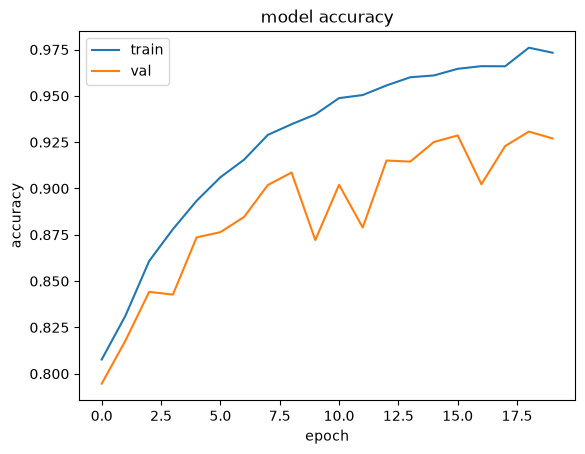

In [24]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

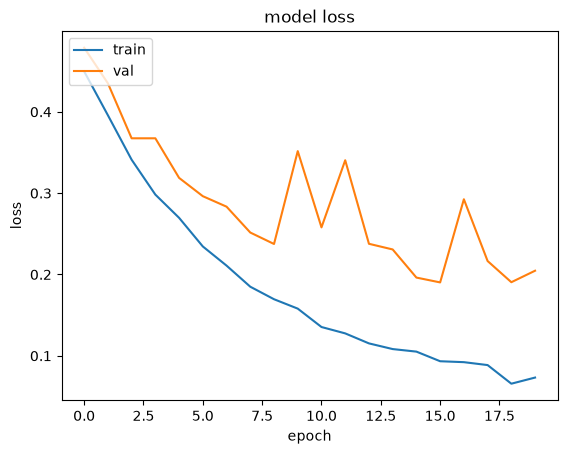

In [25]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [26]:
from sklearn.metrics import confusion_matrix, accuracy_score

y_test = test_images.labels # set y_test to the expected output
print(classification_report(y_test, pred2))
print("Accuracy of the Model:","{:.1f}%".format(accuracy_score(y_test, pred2)*100))

                   precision    recall  f1-score   support

    Mild Demented       0.96      0.97      0.97      2693
Moderate Demented       1.00      0.99      0.99      1977
     Non Demented       0.89      0.94      0.92      2811
Very MildDemented       0.93      0.88      0.91      2715

         accuracy                           0.94     10196
        macro avg       0.95      0.94      0.95     10196
     weighted avg       0.94      0.94      0.94     10196

Accuracy of the Model: 94.2%


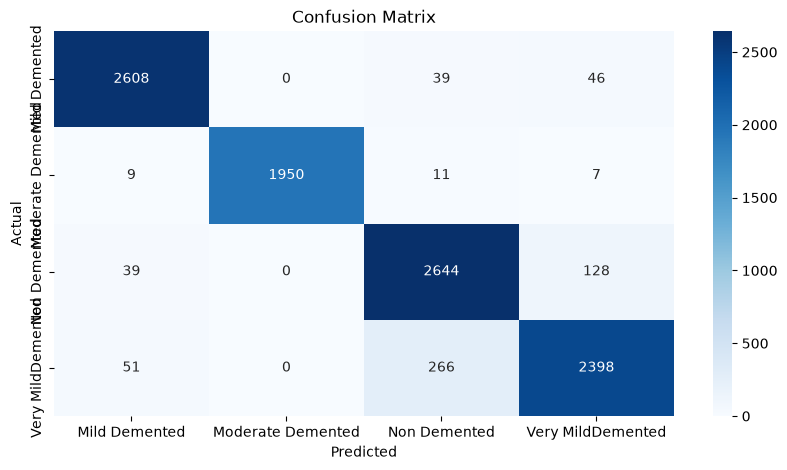

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_labels = ['Mild Demented', 'Moderate Demented', 'Non Demented', 'Very MildDemented']

cm = confusion_matrix(y_test, pred2)

plt.figure(figsize=(10, 5))
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cmap='Blues')

plt.xticks(ticks=[0.5, 1.5, 2.5, 3.5], labels=class_labels)
plt.yticks(ticks=[0.5, 1.5, 2.5, 3.5], labels=class_labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()